1.1 Importação das bibliotecas


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.genmod.generalized_linear_model import GLM
from statsmodels.genmod import families
from scipy import stats

1.2 Importação do conjunto de dados


In [ ]:
url = "https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/MASS/quine.csv"
df = pd.read_csv(url)

if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

df.head()

,rownames,Eth,Sex,Age,Lrn,Days
0,1,A,M,F0,SL,2
1,2,A,M,F0,SL,11
2,3,A,M,F0,SL,14
3,4,A,M,F0,AL,5
4,5,A,M,F0,AL,5


1.3 Inspeção de estrutura e tipos de dados


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 146 entries, 0 to 145
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   rownames  146 non-null    int64 
 1   Eth       146 non-null    object
 2   Sex       146 non-null    object
 3   Age       146 non-null    object
 4   Lrn       146 non-null    object
 5   Days      146 non-null    int64 
dtypes: int64(2), object(4)
memory usage: 7.0+ KB


1.4 Ajuste e padronização dos tipos de variáveis


In [ ]:
df['Eth'] = df['Eth'].astype('category')
df['Sex'] = df['Sex'].astype('category')
df['Age'] = df['Age'].astype('category')
df['Lrn'] = df['Lrn'].astype('category')
df['Days'] = df['Days'].astype(int)

df.dtypes

,0
rownames,int64
Eth,category
Sex,category
Age,category
Lrn,category
Days,int64


2.2 Verificação de dados ausentes e desbalanceamento


In [ ]:
missing_values = df.isna().sum()

crosstab_all = pd.crosstab(
    index=[df['Eth'], df['Sex'], df['Lrn']],
    columns=df['Age'],
    dropna=False
)

missing_values, crosstab_all

(rownames    0
 Eth         0
 Sex         0
 Age         0
 Lrn         0
 Days        0
 dtype: int64,
 Age          F0  F1  F2  F3
 Eth Sex Lrn                
 A   F   AL    4   5   1   9
         SL    1  10   8   0
     M   AL    5   2   7   7
         SL    3   3   4   0
 N   F   AL    4   6   1  10
         SL    1  11   9   0
     M   AL    6   2   7   7
         SL    3   7   3   0)

2.4 Definição das categorias de referência


In [ ]:
df['Eth'] = df['Eth'].cat.set_categories(['N', 'A'])
df['Sex'] = df['Sex'].cat.set_categories(['F', 'M'])
df['Age'] = df['Age'].cat.set_categories(['F1', 'F0', 'F2', 'F3'])
df['Lrn'] = df['Lrn'].cat.set_categories(['AL', 'SL'])

reference_categories = {col: df[col].mode()[0] for col in ['Eth', 'Sex', 'Age', 'Lrn']}

print(reference_categories)

{'Eth': 'N', 'Sex': 'F', 'Age': 'F1', 'Lrn': 'AL'}


3.2 Cálculo das estatísticas descritivas de Days


In [ ]:
stats_days = pd.Series({
    'Minimo': df['Days'].min(),
    'Q1': df['Days'].quantile(0.25),
    'Mediana': df['Days'].median(),
    'Media': df['Days'].mean(),
    'Q3': df['Days'].quantile(0.75),
    'Maximo': df['Days'].max(),
    'Variancia': df['Days'].var(),
    'Desvio_Padrao': df['Days'].std()
})

stats_days

,0
Minimo,0.000000
Q1,5.000000
Mediana,11.000000
Media,16.458904
Q3,22.750000
Maximo,81.000000
Variancia,264.167265
Desvio_Padrao,16.253223


3.3 Tabela de frequências e gráfico da distribuição de Days


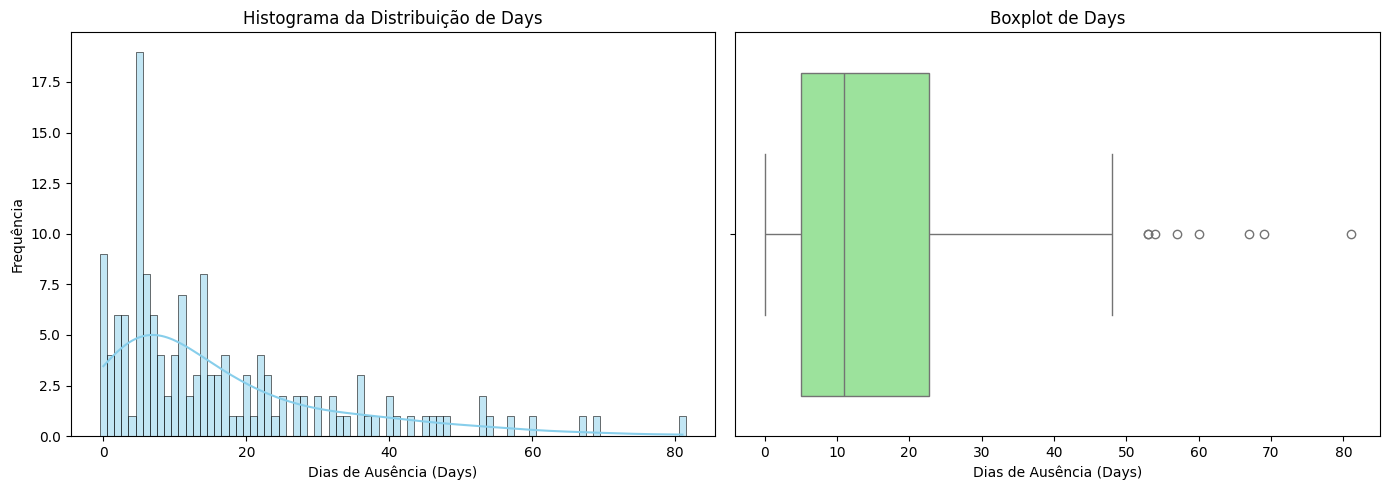

,Frequencia_Absoluta,Frequencia_Relativa
Days,,
0,9,0.061644
1,4,0.027397
2,6,0.041096
3,6,0.041096
4,1,0.006849
5,19,0.130137
6,8,0.054795
7,6,0.041096
8,4,0.027397


In [ ]:
freq_table = pd.DataFrame({
    'Frequencia_Absoluta': df['Days'].value_counts().sort_index(),
    'Frequencia_Relativa': df['Days'].value_counts(normalize=True).sort_index()
})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['Days'], kde=True, ax=axes[0], color='skyblue', discrete=True)
axes[0].set_title('Histograma da Distribuição de Days')
axes[0].set_xlabel('Dias de Ausência (Days)')
axes[0].set_ylabel('Frequência')

sns.boxplot(x=df['Days'], ax=axes[1], color='lightgreen')
axes[1].set_title('Boxplot de Days')
axes[1].set_xlabel('Dias de Ausência (Days)')

plt.tight_layout()
plt.savefig('hist_box.png')
plt.show()

freq_table.head(10)

3.5 Cálculo da proporção observada de zeros


In [ ]:
p0_observed = (df['Days'] == 0).mean()
p0_observed

np.float64(0.06164383561643835)

3.6 Comparação das ausências por covariáveis (Tabelas e Gráficos)


/tmp/ipykernel_546/4082288227.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Eth', y='Days', ax=axes[0, 0], palette='Set2')
/tmp/ipykernel_546/4082288227.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Sex', y='Days', ax=axes[0, 1], palette='Set2')
/tmp/ipykernel_546/4082288227.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Age', y='Days', ax=axes[1, 0], palette='Set2')
/tmp/ipykernel_546/4082288227.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be

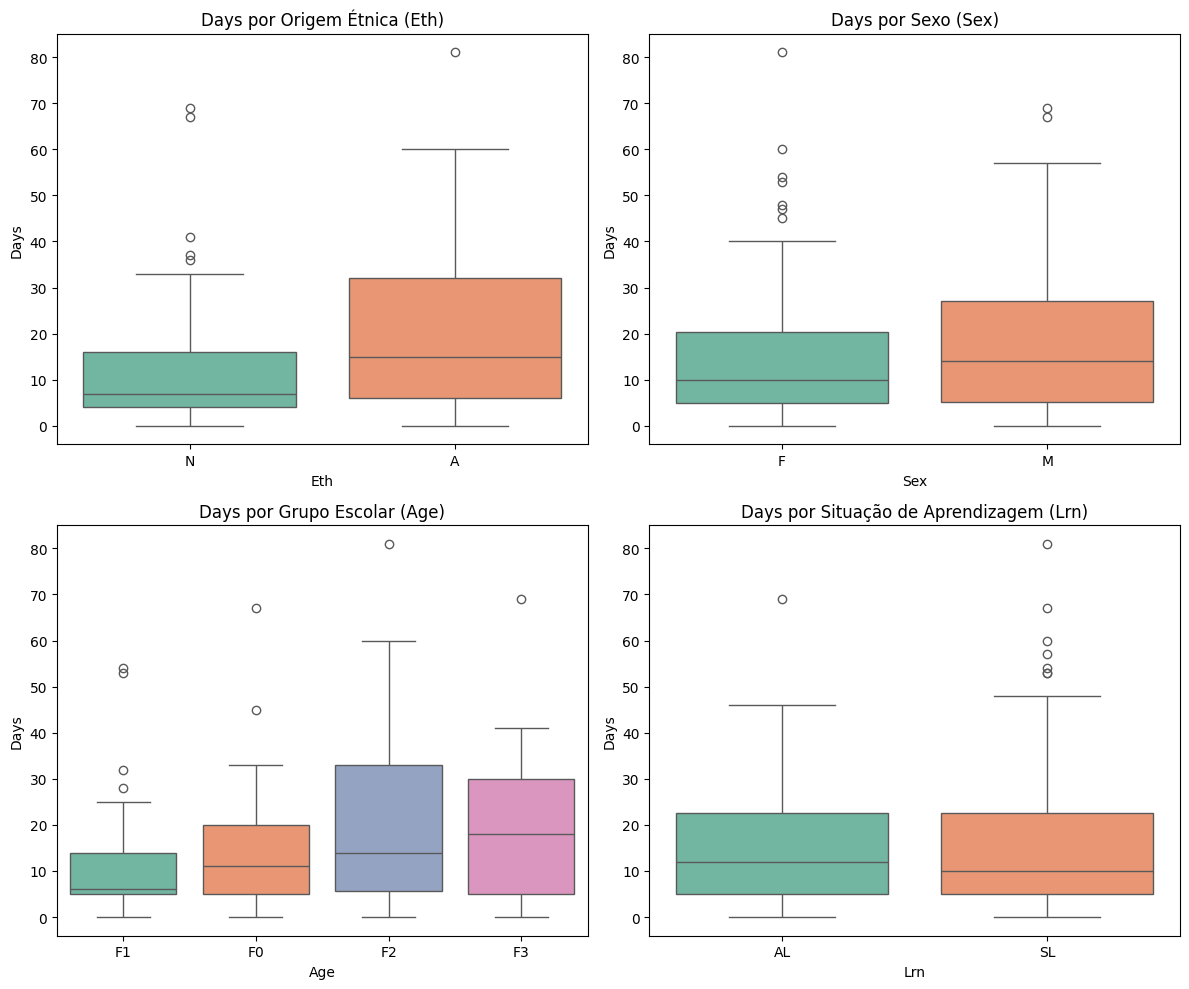

--- Tabela para Eth ---
     Tamanho_Grupo      Media  Mediana   Variancia
Eth                                               
N               77  12.181818      7.0  183.887560
A               69  21.231884     15.0  313.945439


--- Tabela para Sex ---
     Tamanho_Grupo      Media  Mediana   Variancia
Sex                                               
F               80  15.225000     10.0  253.796835
M               66  17.954545     14.0  276.690210


--- Tabela para Age ---
     Tamanho_Grupo      Media  Mediana   Variancia
Age                                               
F1              46  11.152174      6.0  135.509662
F0              27  14.851852     11.0  218.900285
F2              40  21.050000     14.0  405.484615
F3              33  19.606061     18.0  255.183712


--- Tabela para Lrn ---
     Tamanho_Grupo      Media  Mediana   Variancia
Lrn                                               
AL              83  15.819277     12.0  193.491331
SL              63  17.301587  

In [ ]:
covariates = ['Eth', 'Sex', 'Age', 'Lrn']

summary_tables = {}
for col in covariates:
    summary_tables[col] = df.groupby(col, observed=False)['Days'].agg(
        Tamanho_Grupo='count',
        Media='mean',
        Mediana='median',
        Variancia='var'
    )

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

sns.boxplot(data=df, x='Eth', y='Days', ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('Days por Origem Étnica (Eth)')

sns.boxplot(data=df, x='Sex', y='Days', ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Days por Sexo (Sex)')

sns.boxplot(data=df, x='Age', y='Days', ax=axes[1, 0], palette='Set2')
axes[1, 0].set_title('Days por Grupo Escolar (Age)')

sns.boxplot(data=df, x='Lrn', y='Days', ax=axes[1, 1], palette='Set2')
axes[1, 1].set_title('Days por Situação de Aprendizagem (Lrn)')

plt.tight_layout()
plt.savefig("boxplot_covariates.png")
plt.show()

for col in covariates:
    print(f"--- Tabela para {col} ---")
    print(summary_tables[col])
    print("\n")

5.1 Ajuste do Modelo Principal M1 (Poisson) e Tabela Inferencial

In [ ]:
model_m1 = smf.glm(
    formula='Days ~ Eth + Sex + Age + Lrn',
    data=df,
    family=families.Poisson()
).fit()

m1_summary = pd.DataFrame({
    'Coeficiente': model_m1.params,
    'Erro_Padrao': model_m1.bse,
    'P_Valor': model_m1.pvalues,
    'IC_Lower_Beta': model_m1.conf_int()[0],
    'IC_Upper_Beta': model_m1.conf_int()[1],
    'Razao_Medias_expBeta': np.exp(model_m1.params),
    'IC_Lower_expBeta': np.exp(model_m1.conf_int()[0]),
    'IC_Upper_expBeta': np.exp(model_m1.conf_int()[1])
})

m1_summary

,Coeficiente,Erro_Padrao,P_Valor,IC_Lower_Beta,IC_Upper_Beta,Razao_Medias_expBeta,IC_Lower_expBeta,IC_Upper_expBeta
Intercept,1.847875,0.066283,4.880575e-171,1.717961,1.977788,6.346316,5.573155,7.226737
Eth[T.A],0.533604,0.041883,3.529275e-37,0.451515,0.615694,1.705067,1.570690,1.850940
Sex[T.M],0.161597,0.042535,1.451733e-04,0.078230,0.244963,1.175386,1.081372,1.277574
Age[T.F0],0.333901,0.070093,1.901158e-06,0.196521,0.471282,1.396405,1.217160,1.602047
Age[T.F2],0.591730,0.056762,1.913425e-25,0.480477,0.702982,1.807112,1.616846,2.019767
Age[T.F3],0.761595,0.070291,2.353590e-27,0.623827,0.899364,2.141690,1.866055,2.458038
Lrn[T.SL],0.348943,0.052043,2.015731e-11,0.246940,0.450946,1.417568,1.280103,1.569796


5.3 Avaliação global de significância dos fatores do Modelo M1


In [ ]:
terms = ['Eth', 'Sex', 'Age', 'Lrn']
anova_list = []

for term in terms:
    formula_reduced = 'Days ~ ' + ' + '.join([t for t in terms if t != term])
    model_reduced = smf.glm(formula=formula_reduced, data=df, family=families.Poisson()).fit()

    lr_stat = model_reduced.deviance - model_m1.deviance
    df_diff = model_reduced.df_resid - model_m1.df_resid
    p_val = stats.chi2.sf(lr_stat, df_diff)

    anova_list.append({
        'Fator': term,
        'Deviance_Drop': lr_stat,
        'GL': df_diff,
        'P_Valor': p_val
    })

anova_m1 = pd.DataFrame(anova_list)
anova_m1

,Fator,Deviance_Drop,GL,P_Valor
0,Eth,166.844763,1,3.616918e-38
1,Sex,14.404090,1,1.474816e-04
2,Age,168.323862,3,2.927576e-36
3,Lrn,45.798008,1,1.310968e-11


5.5 Ajuste e Comparação dos Modelos M0, M1, M2, M3 e M4 (Seleção Hierárquica)


In [ ]:
model_m0 = smf.glm('Days ~ 1', data=df, family=families.Poisson()).fit()
model_m1 = smf.glm('Days ~ Eth + Sex + Age + Lrn', data=df, family=families.Poisson()).fit()
model_m2 = smf.glm('Days ~ Eth + Sex + Age + Lrn + Eth:Sex', data=df, family=families.Poisson()).fit()
model_m3 = smf.glm('Days ~ Eth + Sex + Age + Lrn + Age:Lrn', data=df, family=families.Poisson()).fit()
model_m4 = smf.glm('Days ~ Eth + Sex + Age + Lrn + Eth:Age + Age:Lrn', data=df, family=families.Poisson()).fit()

models_dict = {'M0': model_m0, 'M1': model_m1, 'M2': model_m2, 'M3': model_m3, 'M4': model_m4}

comparison_table = pd.DataFrame([
    {
        'Modelo': name,
        'Formula': mod.model.formula,
        'Deviance': mod.deviance,
        'GL_Residuos': mod.df_resid,
        'AIC': mod.aic,
        'BIC': mod.bic_llf
    }
    for name, mod in models_dict.items()
])

comparison_table

/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


,Modelo,Formula,Deviance,GL_Residuos,AIC,BIC
0,M0,Days ~ 1,2073.532761,145,2664.009839,2666.993445
1,M1,Days ~ Eth + Sex + Age + Lrn,1696.706552,139,2299.183630,2320.068877
2,M2,Days ~ Eth + Sex + Age + Lrn + Eth:Sex,1674.873708,138,2279.350786,2303.219639
3,M3,Days ~ Eth + Sex + Age + Lrn + Age:Lrn,1687.936173,137,2294.413251,2321.265711
4,M4,Days ~ Eth + Sex + Age + Lrn + Eth:Age + Age:Lrn,1535.217408,134,2147.694486,2183.497765


5.6 Teste de Razão de Verossimilhança (LRT) entre Modelos Aninhados


In [ ]:
def lrt(model_null, model_alt):
    lr_stat = model_null.deviance - model_alt.deviance
    df_diff = model_null.df_resid - model_alt.df_resid
    p_val = stats.chi2.sf(lr_stat, df_diff)
    return {'Estadistica_LR': lr_stat, 'GL_Diferenca': df_diff, 'P_Valor': p_val}

lrt_results = pd.DataFrame([
    {'Comparacao': 'M0 vs M1', **lrt(model_m0, model_m1)},
    {'Comparacao': 'M1 vs M2', **lrt(model_m1, model_m2)},
    {'Comparacao': 'M1 vs M3', **lrt(model_m1, model_m3)},
    {'Comparacao': 'M3 vs M4', **lrt(model_m3, model_m4)}
])

lrt_results

,Comparacao,Estadistica_LR,GL_Diferenca,P_Valor
0,M0 vs M1,376.826208,6,2.673195e-78
1,M1 vs M2,21.832844,1,2.974644e-06
2,M1 vs M3,8.770379,2,1.246053e-02
3,M3 vs M4,152.718765,3,6.827223e-33


5.8 Predição para quatro perfis de estudantes no modelo selecionado


In [ ]:
selected_model = model_m1

profiles = pd.DataFrame({
    'Perfil': ['Perfil 1 (Referencia)', 'Perfil 2', 'Perfil 3', 'Perfil 4'],
    'Eth': ['N', 'A', 'N', 'A'],
    'Sex': ['F', 'F', 'M', 'M'],
    'Age': ['F0', 'F0', 'F3', 'F3'],
    'Lrn': ['AL', 'AL', 'SL', 'SL']
})

pred_res = selected_model.get_prediction(profiles)
pred_summary = pred_res.summary_frame(alpha=0.05)

profiles_output = pd.concat([
    profiles,
    pred_summary[['mean', 'mean_ci_lower', 'mean_ci_upper']].rename(
        columns={'mean': 'Media_Prevista', 'mean_ci_lower': 'IC_Lower', 'mean_ci_upper': 'IC_Upper'}
    )
], axis=1)

profiles_output

,Perfil,Eth,Sex,Age,Lrn,Media_Prevista,IC_Lower,IC_Upper
0,Perfil 1 (Referencia),N,F,F0,AL,8.862030,7.758645,10.122332
1,Perfil 2,A,F,F0,AL,15.110354,13.311171,17.152721
2,Perfil 3,N,M,F3,SL,22.646590,19.494503,26.308341
3,Perfil 4,A,M,F3,SL,38.613950,33.404076,44.636383


6.1 Diagnóstico de Dispersão no Modelo Poisson (E1 e E2)

In [ ]:
phi_pearson = np.sum(selected_model.resid_pearson**2) / selected_model.df_resid
phi_deviance = selected_model.deviance / selected_model.df_resid

dispersion_summary = pd.DataFrame({
    'Metrica': ['Dispersao de Pearson (phi_P)', 'Razao Deviance / GL'],
    'Valor': [phi_pearson, phi_deviance]
})

dispersion_summary

,Metrica,Valor
0,Dispersao de Pearson (phi_P),13.166843
1,Razao Deviance / GL,12.206522


6.3 Avaliação do Ajuste de Zeros (Questão E3)


In [ ]:
mu_hat_poisson = selected_model.fittedvalues
p0_predicted_poisson = np.mean(np.exp(-mu_hat_poisson))

zero_comparison = pd.DataFrame({
    'Proporcao_Observada_p0': [p0_observed],
    'Proporcao_Esperada_Poisson_p0': [p0_predicted_poisson]
})

zero_comparison

,Proporcao_Observada_p0,Proporcao_Esperada_Poisson_p0
0,0.061644,0.000097


6.5 Ajuste dos Modelos Quase-Poisson e Binomial Negativo

In [ ]:
model_poisson = smf.glm(
    formula='Days ~ Eth + Sex + Age + Lrn',
    data=df,
    family=families.Poisson()
).fit()

model_quasipoisson = smf.glm(
    formula='Days ~ Eth + Sex + Age + Lrn',
    data=df,
    family=families.Poisson()
).fit(scale=phi_pearson)

model_nb = smf.glm(
    formula='Days ~ Eth + Sex + Age + Lrn',
    data=df,
    family=families.NegativeBinomial(link=sm.families.links.Log())
).fit()

/tmp/ipykernel_546/3788779640.py:16: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  family=families.NegativeBinomial(link=sm.families.links.Log())


6.6 Tabela Comparativa de Parâmetros entre Famílias (E4)


In [ ]:
comp_params = pd.DataFrame({
    'Poisson_Beta': model_poisson.params,
    'Poisson_SE': model_poisson.bse,
    'QuasePoisson_Beta': model_quasipoisson.params,
    'QuasePoisson_SE': model_quasipoisson.bse,
    'BinomialNegativa_Beta': model_nb.params,
    'BinomialNegativa_SE': model_nb.bse
})

comp_params

,Poisson_Beta,Poisson_SE,QuasePoisson_Beta,QuasePoisson_SE,BinomialNegativa_Beta,BinomialNegativa_SE
Intercept,1.847875,0.066283,1.847875,0.240517,1.878010,0.235565
Eth[T.A],0.533604,0.041883,0.533604,0.151978,0.570051,0.171634
Sex[T.M],0.161597,0.042535,0.161597,0.154341,0.080385,0.178979
Age[T.F0],0.333901,0.070093,0.333901,0.254342,0.449765,0.268027
Age[T.F2],0.591730,0.056762,0.591730,0.205969,0.536005,0.228140
Age[T.F3],0.761595,0.070291,0.761595,0.255060,0.805675,0.274724
Lrn[T.SL],0.348943,0.052043,0.348943,0.188844,0.290167,0.208473


6.7 Resposta teórica da Questão E4 e E5


In [ ]:
formula = 'Days ~ Eth + Sex + Age + Lrn'
mod_poisson = smf.glm(formula=formula, data=df, family=sm.families.Poisson()).fit()
mod_quase_poisson = smf.glm(formula=formula, data=df, family=sm.families.Poisson()).fit(scale='X2')

mod_bn = smf.negativebinomial(formula=formula, data=df).fit(disp=False)

print("--- Comparação por Critérios de Informação ---")
print(f"Poisson           -> AIC: {mod_poisson.aic:.2f} | BIC: {mod_poisson.bic_llf:.2f}")
print(f"Binomial Negativo -> AIC: {mod_bn.aic:.2f} | BIC: {mod_bn.bic:.2f}")

print("\n--- Diagnóstico de Dispersão (Quase-Poisson) ---")
phi = mod_poisson.pearson_chi2 / mod_poisson.df_resid
print(f"Parâmetro de dispersão estimado (phi): {phi:.2f}")
if phi > 1.5:
    print("Conclusão: Forte evidência de sobredispersão. Erros-padrão do modelo Poisson estão subestimados.")

--- Comparação por Critérios de Informação ---
Poisson           -> AIC: 2299.18 | BIC: 2320.07
Binomial Negativo -> AIC: 1109.15 | BIC: 1133.02

--- Diagnóstico de Dispersão (Quase-Poisson) ---
Parâmetro de dispersão estimado (phi): 13.17
Conclusão: Forte evidência de sobredispersão. Erros-padrão do modelo Poisson estão subestimados.


7.1 Análise Visual de Resíduos Padronizados (F1)


/tmp/ipykernel_546/3649826511.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Age', y=residuals_deviance, ax=axes[1, 1], palette='Set2')


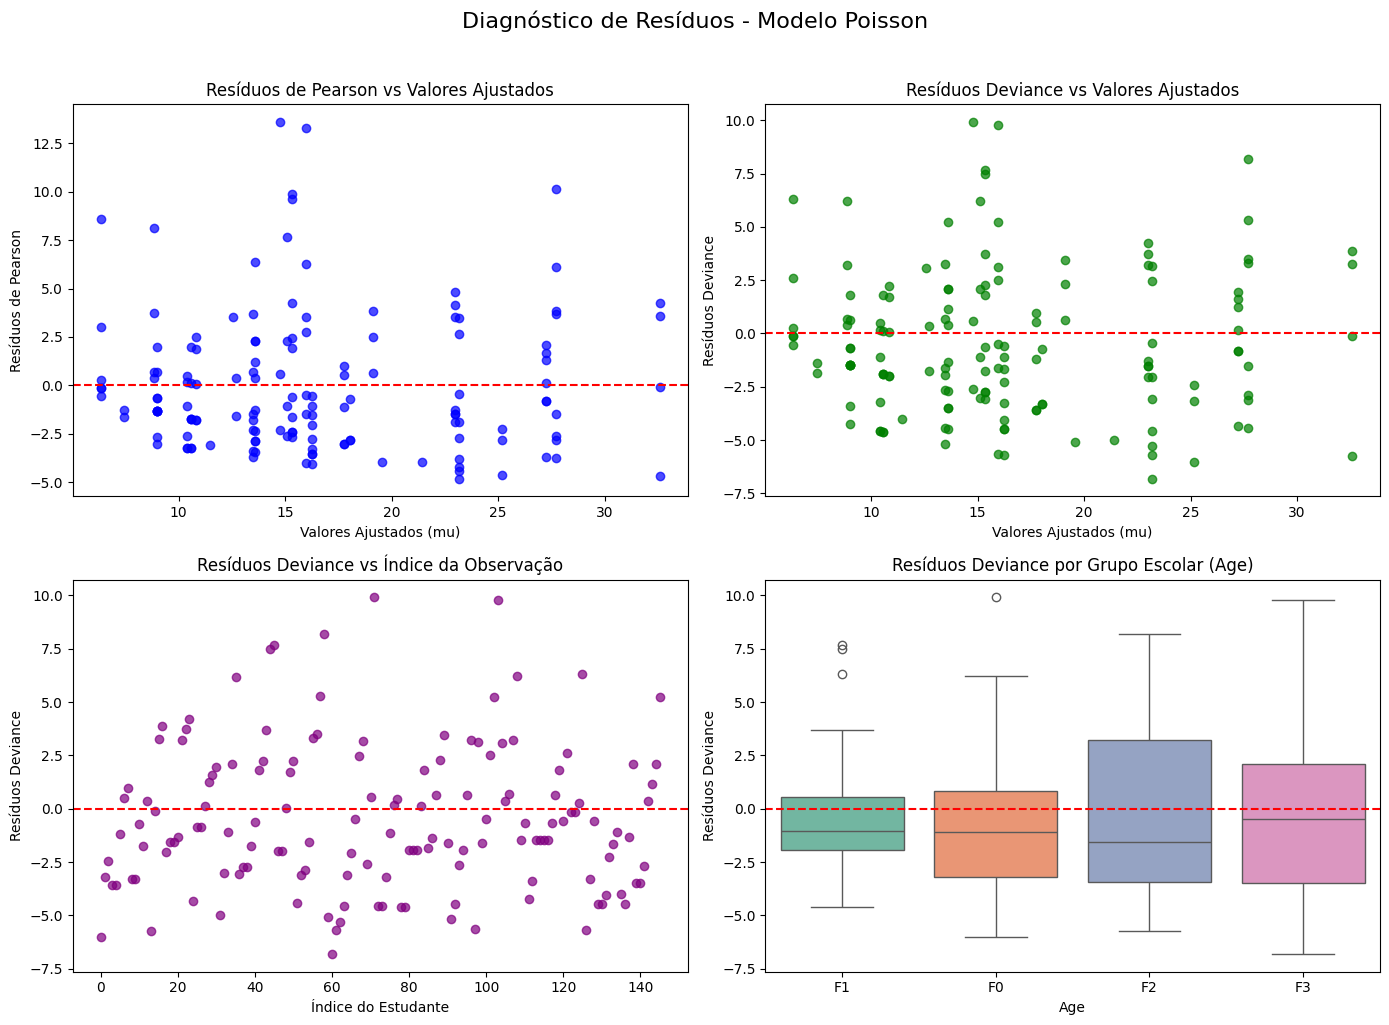

/tmp/ipykernel_546/3649826511.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Age', y=residuals_deviance, ax=axes[1, 1], palette='Set2')


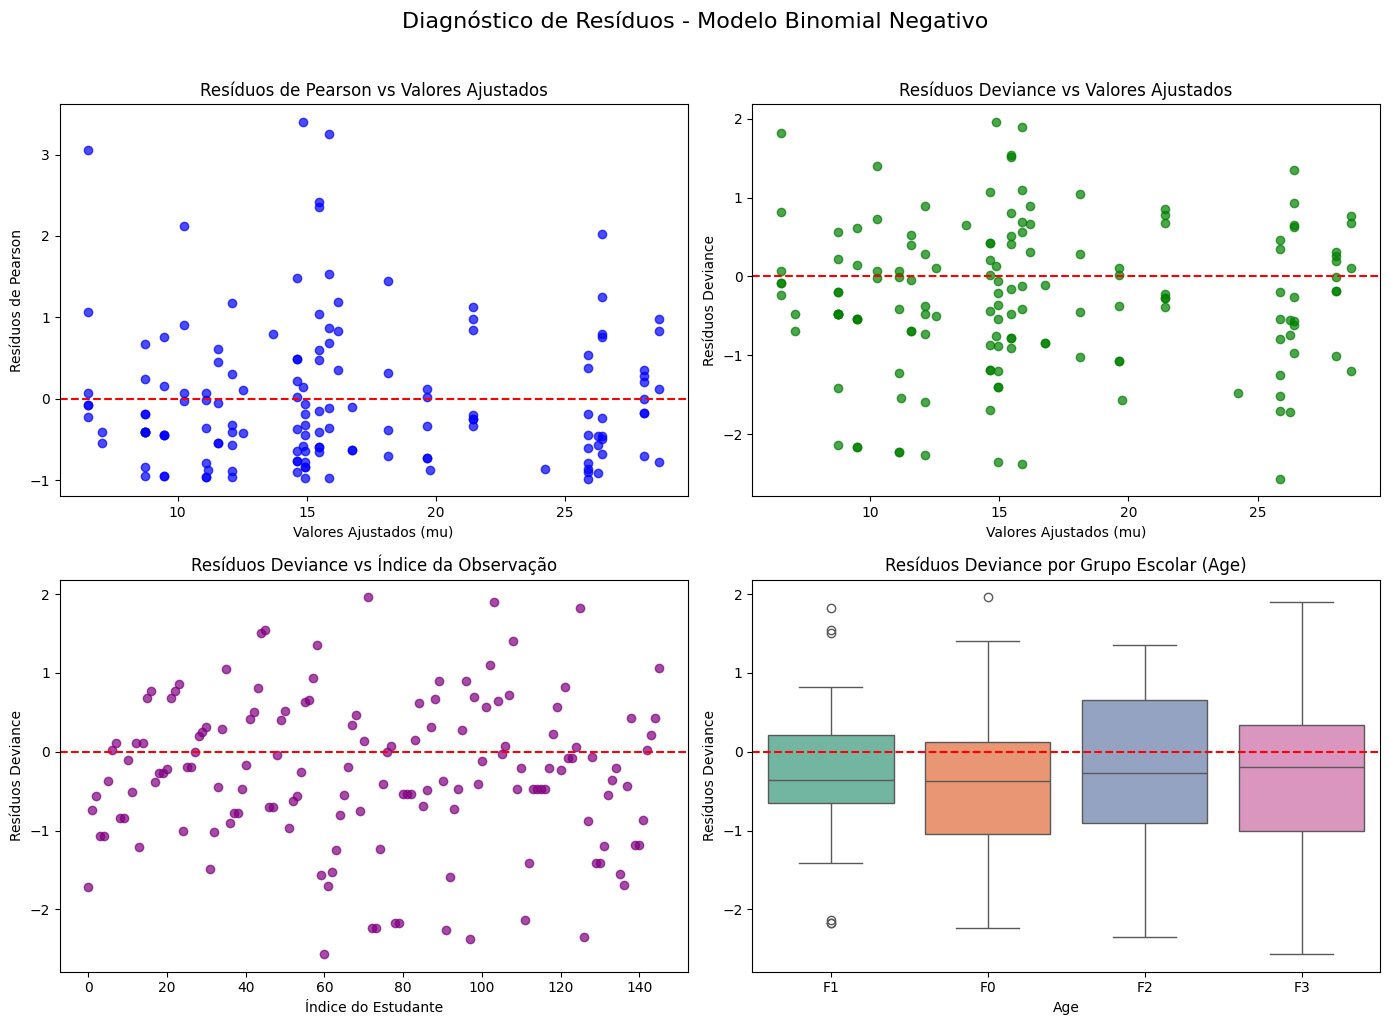

In [ ]:
def plot_diagnostics(model, df, title_suffix, filename):
    residuals_pearson = model.resid_pearson
    residuals_deviance = model.resid_deviance
    fitted_values = model.fittedvalues

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(f'Diagnóstico de Resíduos - Modelo {title_suffix}', fontsize=16, y=1.02)

    axes[0, 0].scatter(fitted_values, residuals_pearson, alpha=0.7, color='blue')
    axes[0, 0].axhline(0, color='red', linestyle='--')
    axes[0, 0].set_title('Resíduos de Pearson vs Valores Ajustados')
    axes[0, 0].set_xlabel('Valores Ajustados (mu)')
    axes[0, 0].set_ylabel('Resíduos de Pearson')

    axes[0, 1].scatter(fitted_values, residuals_deviance, alpha=0.7, color='green')
    axes[0, 1].axhline(0, color='red', linestyle='--')
    axes[0, 1].set_title('Resíduos Deviance vs Valores Ajustados')
    axes[0, 1].set_xlabel('Valores Ajustados (mu)')
    axes[0, 1].set_ylabel('Resíduos Deviance')

    axes[1, 0].scatter(df.index, residuals_deviance, alpha=0.7, color='purple')
    axes[1, 0].axhline(0, color='red', linestyle='--')
    axes[1, 0].set_title('Resíduos Deviance vs Índice da Observação')
    axes[1, 0].set_xlabel('Índice do Estudante')
    axes[1, 0].set_ylabel('Resíduos Deviance')

    sns.boxplot(data=df, x='Age', y=residuals_deviance, ax=axes[1, 1], palette='Set2')
    axes[1, 1].axhline(0, color='red', linestyle='--')
    axes[1, 1].set_title('Resíduos Deviance por Grupo Escolar (Age)')
    axes[1, 1].set_ylabel('Resíduos Deviance')

    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()

plot_diagnostics(mod_poisson, df, "Poisson", "Residuos_Poisson.png")

plot_diagnostics(model_nb, df, "Binomial Negativo", "Residuos_BN.png")

7.2 Gráfico Quantil-Quantil com Envelope Simulado (F2)


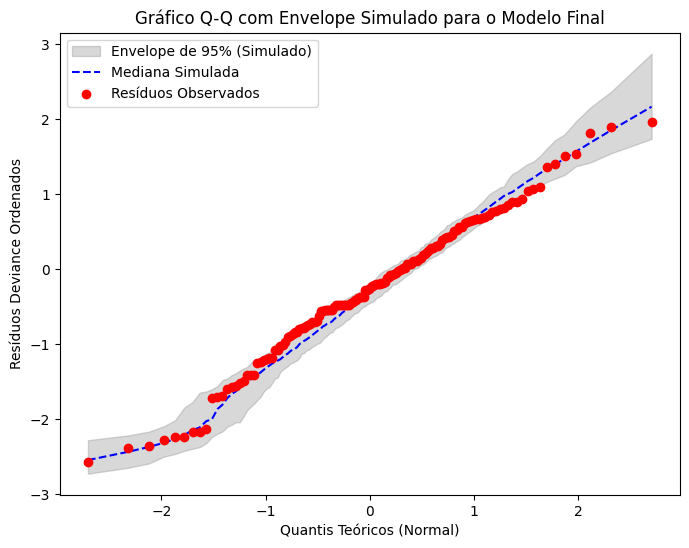

In [ ]:
n_simulations = 100
n_obs = len(df)

simulated_residuals = np.zeros((n_obs, n_simulations))

for s in range(n_simulations):
    y_sim = np.random.negative_binomial(
        n=1/model_nb.model.family.alpha if hasattr(model_nb.model.family, 'alpha') else 1,
        p=1/(1 + model_nb.fittedvalues * (model_nb.model.family.alpha if hasattr(model_nb.model.family, 'alpha') else 1))
    )
    df_sim = df.copy()
    df_sim['Days_Sim'] = y_sim

    try:
        model_sim = smf.glm('Days_Sim ~ Eth + Sex + Age + Lrn', data=df_sim, family=model_nb.family).fit()
        simulated_residuals[:, s] = np.sort(model_sim.resid_deviance)
    except:
        simulated_residuals[:, s] = np.sort(model_nb.resid_deviance)

lower_env = np.percentile(simulated_residuals, 2.5, axis=1)
upper_env = np.percentile(simulated_residuals, 97.5, axis=1)
median_env = np.percentile(simulated_residuals, 50, axis=1)

sorted_obs_residuals = np.sort(model_nb.resid_deviance)
theoretical_quantiles = stats.norm.ppf(np.linspace(0.5/n_obs, 1 - 0.5/n_obs, n_obs))

plt.figure(figsize=(8, 6))
plt.fill_between(theoretical_quantiles, lower_env, upper_env, color='gray', alpha=0.3, label='Envelope de 95% (Simulado)')
plt.plot(theoretical_quantiles, median_env, color='blue', linestyle='--', label='Mediana Simulada')
plt.scatter(theoretical_quantiles, sorted_obs_residuals, color='red', zorder=5, label='Resíduos Observados')

plt.title('Gráfico Q-Q com Envelope Simulado para o Modelo Final')
plt.xlabel('Quantis Teóricos (Normal)')
plt.ylabel('Resíduos Deviance Ordenados')
plt.legend()
plt.savefig('Q-Q.png')
plt.show()

7.4 Diagnóstico de Influência e Alavancagem (F3)


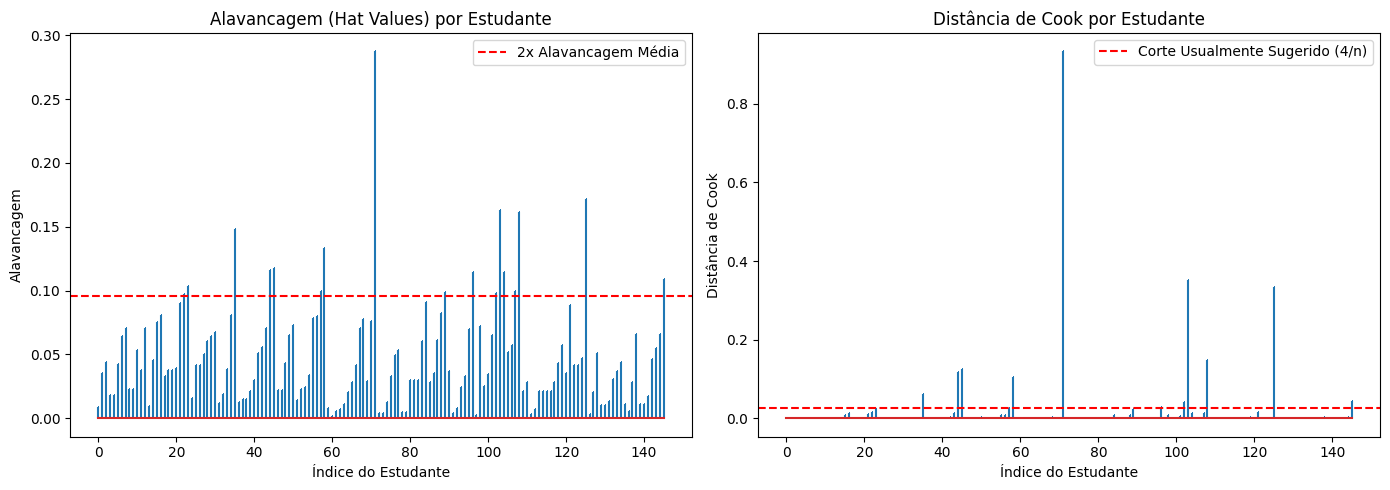

In [ ]:
influence = model_nb.get_influence()
hat_matrix_diag = influence.hat_matrix_diag
cooks_distance = influence.cooks_distance[0]

df_diag = df.copy()
df_diag['Valores_Ajustados'] = model_nb.fittedvalues
df_diag['Residuo_Deviance'] = model_nb.resid_deviance
df_diag['Alavancagem'] = hat_matrix_diag
df_diag['Distancia_Cook'] = cooks_distance

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].stem(df_diag.index, df_diag['Alavancagem'], markerfmt=",")
axes[0].axhline(2 * df_diag['Alavancagem'].mean(), color='red', linestyle='--', label='2x Alavancagem Média')
axes[0].set_title('Alavancagem (Hat Values) por Estudante')
axes[0].set_xlabel('Índice do Estudante')
axes[0].set_ylabel('Alavancagem')
axes[0].legend()

axes[1].stem(df_diag.index, df_diag['Distancia_Cook'], markerfmt=",")
axes[1].axhline(4 / len(df_diag), color='red', linestyle='--', label='Corte Usualmente Sugerido (4/n)')
axes[1].set_title('Distância de Cook por Estudante')
axes[1].set_xlabel('Índice do Estudante')
axes[1].set_ylabel('Distância de Cook')
axes[1].legend()

plt.tight_layout()
plt.savefig('Alavanca.png')
plt.show()

7.6 Investigação de Estudantes Críticos (F4)


In [ ]:
top5_influential = df_diag.sort_values(by='Distancia_Cook', ascending=False).head(5)

top5_output = top5_influential[[
    'Days', 'Eth', 'Sex', 'Age', 'Lrn',
    'Valores_Ajustados', 'Residuo_Deviance', 'Alavancagem', 'Distancia_Cook'
]]

top5_output

,Days,Eth,Sex,Age,Lrn,Valores_Ajustados,Residuo_Deviance,Alavancagem,Distancia_Cook
71,67,N,M,F0,SL,14.854861,1.957723,0.287458,0.933799
103,69,N,M,F3,AL,15.864281,1.898259,0.163428,0.352052
125,28,N,F,F1,AL,6.540478,1.818869,0.171543,0.333401
108,33,N,F,F0,AL,10.255100,1.399884,0.161749,0.147392
45,54,A,F,F1,SL,15.459574,1.541024,0.118033,0.126537


7.8 Análise de Sensibilidade (F5)


In [ ]:
influential_indices = top5_influential.index
df_reduced = df.drop(index=influential_indices)

model_nb_reduced = smf.glm(
    formula='Days ~ Eth + Sex + Age + Lrn',
    data=df_reduced,
    family=families.NegativeBinomial(link=sm.families.links.Log())
).fit()

sensitivity_comp = pd.DataFrame({
    'Beta_Modelo_Completo': model_nb.params,
    'SE_Modelo_Completo': model_nb.bse,
    'ExpBeta_Completo': np.exp(model_nb.params),
    'Beta_Sem_Influentes': model_nb_reduced.params,
    'SE_Sem_Influentes': model_nb_reduced.bse,
    'ExpBeta_Sem_Influentes': np.exp(model_nb_reduced.params)
})

sensitivity_comp

/tmp/ipykernel_546/342308443.py:7: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  family=families.NegativeBinomial(link=sm.families.links.Log())


,Beta_Modelo_Completo,SE_Modelo_Completo,ExpBeta_Completo,Beta_Sem_Influentes,SE_Sem_Influentes,ExpBeta_Sem_Influentes
Intercept,1.878010,0.235565,6.540478,1.713505,0.245677,5.548377
Eth[T.A],0.570051,0.171634,1.768358,0.698832,0.175534,2.011401
Sex[T.M],0.080385,0.178979,1.083704,0.043781,0.183493,1.044753
Age[T.F0],0.449765,0.268027,1.567944,0.324144,0.279819,1.382847
Age[T.F2],0.536005,0.228140,1.709165,0.671810,0.231236,1.957778
Age[T.F3],0.805675,0.274724,2.238206,0.826235,0.282378,2.284701
Lrn[T.SL],0.290167,0.208473,1.336651,0.245885,0.215283,1.278753


8.1 Validação Cruzada Estratificada 10-Fold (G1 e G2)

In [ ]:
from sklearn.model_selection import StratifiedKFold

df['Strata'] = df['Eth'].astype(str) + '_' + df['Lrn'].astype(str)

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

cv_results = []

for train_idx, test_idx in skf.split(df, df['Strata']):
    train_data = df.iloc[train_idx]
    test_data = df.iloc[test_idx]

    m1_cv = smf.glm('Days ~ Eth + Sex + Age + Lrn', data=train_data, family=families.Poisson()).fit()
    pred_poisson = m1_cv.predict(test_data)

    nb_cv = smf.glm('Days ~ Eth + Sex + Age + Lrn', data=train_data, family=families.NegativeBinomial(link=sm.families.links.Log())).fit()
    pred_nb = nb_cv.predict(test_data)

    y_true = test_data['Days']

    dev_p = 2 * np.sum(y_true * np.log(np.maximum(y_true, 1) / pred_poisson) - (y_true - pred_poisson))
    mae_p = np.mean(np.abs(y_true - pred_poisson))
    rmse_p = np.sqrt(np.mean((y_true - pred_poisson)**2))

    dev_nb = 2 * np.sum(y_true * np.log(np.maximum(y_true, 1) / pred_nb) - (y_true - pred_nb))
    mae_nb = np.mean(np.abs(y_true - pred_nb))
    rmse_nb = np.sqrt(np.mean((y_true - pred_nb)**2))

    cv_results.append({
        'Dev_Poisson': dev_p, 'MAE_Poisson': mae_p, 'RMSE_Poisson': rmse_p,
        'Dev_NB': dev_nb, 'MAE_NB': mae_nb, 'RMSE_NB': rmse_nb
    })

cv_df = pd.DataFrame(cv_results)

cv_summary = pd.DataFrame({
    'Modelo': ['Poisson (M1)', 'Binomial Negativo (M1)'],
    'Deviance_CV_Media': [cv_df['Dev_Poisson'].mean(), cv_df['Dev_NB'].mean()],
    'MAE_CV_Medio': [cv_df['MAE_Poisson'].mean(), cv_df['MAE_NB'].mean()],
    'RMSE_CV_Medio': [cv_df['RMSE_Poisson'].mean(), cv_df['RMSE_NB'].mean()]
})

cv_summary

/tmp/ipykernel_546/1642444686.py:16: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  nb_cv = smf.glm('Days ~ Eth + Sex + Age + Lrn', data=train_data, family=families.NegativeBinomial(link=sm.families.links.Log())).fit()
/tmp/ipykernel_546/1642444686.py:16: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  nb_cv = smf.glm('Days ~ Eth + Sex + Age + Lrn', data=train_data, family=families.NegativeBinomial(link=sm.families.links.Log())).fit()
/tmp/ipykernel_546/1642444686.py:16: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  nb_cv = smf.glm('Days ~ Eth + Sex + Age + Lrn', data=train_data, family=families.NegativeBinomial(link=sm.families.links.Log())).fit()
/tmp/ipykernel_546/1642444686.py:16: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  nb_cv = smf.glm('Days ~ Eth + Sex + Age + L

,Modelo,Deviance_CV_Media,MAE_CV_Medio,RMSE_CV_Medio
0,Poisson (M1),193.406872,11.683903,15.162297
1,Binomial Negativo (M1),194.344074,11.756893,15.313887
